**Métodos Numéricos - MEC301**
# Tarea 2

**Fecha de entrega:** lunes 12 de octubre, 2026

**Integrantes (máximo 2):**
- Constanza Quezada
- Rodrigo Zúñiga

**Instrucciones.**
- Complete este archivo con sus respuestas. **Todo el desarrollo va en el notebook**: no se entrega nada en papel.
- Una vez completado, guarde el archivo como: "*tarea2_apellido1_apellido2.ipynb*".
- Adjunte **únicamente el archivo .ipynb** al buzón de entregas habilitado en la plataforma webcurso. Basta con que lo suba una sola persona del grupo.
- Mantenga los archivos adjuntos (`hot_carriers.py`, `ensayo_bomba.csv`, `curva_rendimiento_bomba.pdf`, `images/`) en la misma carpeta del notebook mientras trabaja.

>**EVITE SANCIONES.** Todas las respuestas deben considerar **exclusivamente** las funciones, metodologías y algoritmos vistos en clases y bibliografía asociada al curso. Soluciones obtenidas mediante inteligencia artificial, o copia de un compañera/o, serán consideradas como plagio, una falta al código de honor y sancionadas con nota 1.0. En el caso de copia, la sanción aplicará también para el facilitador.

**Preguntas de razonamiento**

El símbolo 📝 marca un ítem de razonamiento, que debe responderse en formato *markdown* y no requiere código. **Las ecuaciones deben escribirse en sintaxis LaTeX** siguiendo las sugerencias de la nota al final. **No se acepta una respuesta que sea únicamente el resultado final.** Se evalúa el razonamiento: qué método se eligió, por qué, y qué muestran los resultados.

>**Sugerencia sintaxis LaTeX.** Para una expresión dentro de una línea de texto se usa `$...$`; para una ecuación destacada en su propia línea:
>
>```
>\begin{equation*}
>\int_{x_i}^{x_{i+1}} f(x)\,dx = h f(\bar{x}_i) + O(h^3)
>\end{equation*}
>```
>
>Ejemplos que le servirán en esta tarea:

| lo que escribe | cómo se ve |
|:---|:---|
| `$j_l(x)$`, `$x_{nl}$` | $j_l(x)$, $x_{nl}$ |
| `$\hbar\omega$`, `$E_F$` | $\hbar\omega$, $E_F$ |
| `$\int_0^1 f(\rho)\,d\rho$` | $\int_0^1 f(\rho)\,d\rho$ |
| `$\bar{x}_i = \frac{x_i + x_{i+1}}{2}$` | $\bar{x}_i = \frac{x_i + x_{i+1}}{2}$ |
| `$f''(\bar{x}_i)$` | $f''(\bar{x}_i)$ |
| `$\sum_{i=0}^{n-1} h f(\bar{x}_i)$` | $\sum_{i=0}^{n-1} h f(\bar{x}_i)$ |
| `$O(h^2)$`, `$O(n^3)$` | $O(h^2)$, $O(n^3)$ |
| `$\approx$`, `$\leq$`, `$\times$`, `$\pm$` | $\approx$, $\leq$, $\times$, $\pm$ |

| Item | (a) | (b) | (c) | (d) | (e) | total |
|:---|:-:|:-:|:-:|:-:|:-:|:-:|
| Problema 1 (1.8 pts) | | | | – | – | |
| Problema 2 (1.2 pts) | | | | | – | |
| Problema 3 (1.2 pts) | | | | – | – | |
| Problema 4 (1.8 pts) | | | | | | |
| **Nota final** | – | – | – | – | – | |

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import time

---
## Problema 1 (1.8 puntos) — Portadores calientes en nanopartículas de plata

### Luz solar, plasmones y portadores calientes

Chile tiene en el desierto de Atacama uno de los recursos solares más altos del planeta, y una estrategia nacional que apuesta por producir hidrógeno verde. La forma más directa de producirlo con el sol es la **fotocatálisis**: usar la luz para separar la molécula de agua,

\begin{equation*}
2\,\mathrm{H_2O} \;\longrightarrow\; 2\,\mathrm{H_2} + \mathrm{O_2},
\end{equation*}

una reacción que exige al menos 1.23 eV por cada electrón transferido.

El fotocatalizador clásico es el dióxido de titanio (TiO$_2$). Es barato, abundante y estable en agua. Sin embargo, su brecha de energía de ~3.2 eV solo le permite absorber radiación ultravioleta, cerca del 5 % de la energía solar que llega a la superficie. La luz visible, que es la mayor parte del espectro, lo atraviesa sin producir nada.

Una forma de aprovechar el visible es decorar el semiconductor con **nanopartículas metálicas** de plata u oro, de 5 a 50 nm. En ellas, los electrones de conducción responden a la luz oscilando en conjunto, una excitación llamada **plasmón** (Figura 1a). El plasmón concentra la luz en un volumen mucho menor que su longitud de onda. Por eso, una nanopartícula en resonancia absorbe más luz que la que intercepta su área geométrica.

El plasmón vive unos 10 fs. Al decaer, entrega su energía $\hbar\omega$ a un electrón, que salta desde un nivel bajo la energía de Fermi $E_F$ a uno sobre ella (Figura 1b). Nacen así un **electrón caliente** y un **hueco caliente**. Si el electrón tiene energía suficiente para superar la barrera $\phi_B$ de la interfaz, se inyecta en el semiconductor y participa en la reducción de protones a H$_2$. El hueco que queda en el metal puede oxidar el agua. Con este mecanismo se han demostrado la disociación de H$_2$ sobre oro a temperatura ambiente, el *water splitting* con luz visible y la producción de hidrógeno a partir de etanol (referencias 18 a 27 del artículo [1]).

<center><img src="./images/hot_carriers_esquema.png" width="800"></center>
<center><small><b>Figura 1.</b> (a) La luz excita un plasmón en una nanopartícula de plata. (b) El plasmón decae y promueve un electrón desde un nivel ocupado a uno vacío. Si el electrón caliente supera la barrera $\phi_B$, se inyecta en el semiconductor.</small></center>

La pregunta que decide la utilidad del proceso es **cuántos portadores nacen con energía alta**. El nivel de Fermi ($E_F$) define el cero de energía para los electrones, similar al nivel de líquido cuando se llena un vaso con agua. Un electrón excitado que queda 0.1 eV sobre $E_F$ no cruza ninguna barrera y termina como calor. Esa distribución de energías depende del tamaño de la partícula y del tiempo de vida $\tau$ de los portadores. Es difícil de medir directamente, y por eso se calcula.

En este problema vamos a calcularla siguiendo un modelo simplificado de la versión de Manjavacas et al. [1]. El cálculo descansa en dos herramientas del curso. La **búsqueda de raíces** entrega los niveles de energía de los electrones, y la **integración numérica**, la probabilidad de que un fotón induzca una transición de estado en los electrones o huecos. Son miles de raíces y decenas de miles de integrales. La elección del método decide si el cálculo tarda menos de un segundo o más de veinte minutos.

>**Referencia.** [1] A. Manjavacas, J. G. Liu, V. Kulkarni y P. Nordlander, *Plasmon-Induced Hot Carriers in Metallic Nanoparticles*, ACS Nano **8**, 7630-7638 (2014). [doi: 10.1021/nn502445f](https://doi.org/10.1021/nn502445f)

### El modelo

Los electrones de conducción de la plata se mueven libres dentro de la partícula de radio $a = D/2$ y no pueden salir de ella. Este es el **pozo de potencial esférico infinito**. Al resolver la ecuación de Schrödinger en coordenadas esféricas, la función de onda de cada estado es

\begin{equation*}
\Psi_{nlm}(r,\theta,\varphi) = A_{nl}\, j_l(k r)\, Y_l^m(\theta,\varphi),
\end{equation*}

donde $j_l$ es la **función de Bessel esférica** de orden $l = 0, 1, 2, \ldots$ e $Y_l^m$ son los armónicos esféricos, con $m = -l, \ldots, l$. La condición de borde $\Psi(a) = 0$ exige $j_l(ka) = 0$. Por lo tanto, los valores permitidos de $k$ quedan fijados por los ceros de $j_l$: $k_{nl} = x_{nl}/a$, donde $x_{nl}$ es el $n$-ésimo cero positivo de $j_l(x)$. La energía de cada nivel es

\begin{equation}
E_{nl} = \frac{\hbar^2}{2m_e}\left(\frac{x_{nl}}{a}\right)^2, \qquad \frac{\hbar^2}{2m_e} = 0.0381~\mathrm{eV\,nm^2}.
\tag{1}
\end{equation}

Cada nivel $(n, l)$ contiene $2(2l+1)$ estados: $2l+1$ valores de $m$ y dos de espín. A temperatura cero, los electrones llenan los niveles desde el fondo del pozo hasta la energía de Fermi de la plata, $E_F = 5.49$ eV.

Usaremos la variable adimensional $\rho = r/a \in [0, 1]$, con la cual $j_l(k_{nl} r) = j_l(x_{nl}\rho)$.

**Transiciones.** La luz de energía $\hbar\omega = 3.65$ eV (el plasmón de la plata) induce transiciones desde un nivel ocupado $i$ ($E_i \leq E_F$) a uno vacío $f$ ($E_f > E_F$). La tasa de cada transición sigue la **regla de oro de Fermi** (ec. 1 de [1]):

\begin{equation}
\Gamma_{fi} \propto |M_{fi}|^2\left[\frac{1}{(\hbar\omega - \Delta E)^2 + (\hbar/\tau)^2} + \frac{1}{(\hbar\omega + \Delta E)^2 + (\hbar/\tau)^2}\right], \qquad \Delta E = E_f - E_i .
\tag{2}
\end{equation}

El primer término favorece las transiciones que conservan la energía, $\Delta E \approx \hbar\omega$, con un ancho $\hbar/\tau$ fijado por el tiempo de vida $\tau$ de los portadores (electrones o huecos). El factor $|M_{fi}|^2$ mide qué tan probable es que un fotón induzca una transición $E_i \rightarrow E_f$. Tiene forma cerrada de la forma:

\begin{equation}
|M_{fi}|^2 = S(l_i, l_f)\,\frac{I_{fi}^2}{N_i\,N_f},
\tag{3}
\end{equation}

con la **integral radial** y la **normalización**

\begin{equation*}
I_{fi} = \int_0^1 j_{l_f}(x_f\rho)\, j_{l_i}(x_i\rho)\, \rho^3\, d\rho,
\qquad
N_{nl} = \int_0^1 j_l^2(x_{nl}\rho)\, \rho^2\, d\rho,
\end{equation*}

y el factor angular

\begin{equation*}
S(l_i, l_f) =
\begin{cases}
(l_i + 1)/3 & \text{si } l_f = l_i + 1 \\
l_i/3 & \text{si } l_f = l_i - 1 \\
0 & \text{en otro caso}
\end{cases}
\end{equation*}

**Lo que usted programa.** El archivo `hot_carriers.py` arma la lista de niveles, evalúa la ecuación (2) para todas las transiciones y grafica el resultado. Para eso necesita **dos funciones que usted debe programar**: `raices_jl`, en el ítem (a), y `matriz_transicion`, en el ítem (b).

In [34]:
from scipy.special import spherical_jn       # función de Bessel esférica j_l(x)
from hot_carriers import (estados_pozo, distribucion_hot_carriers, graficar_distribucion,
                          x_de_energia, EF_AG)

EF = EF_AG     # energía de Fermi de la plata, eV
hw = 3.65      # energía del plasmón, eV

### (a) 0.6 pts — Los niveles de energía: raíces de $j_l(x)$

Para $D = 15$ nm, los niveles con energía hasta $E_F + \hbar\omega$ corresponden a ceros de $j_l$ con $x \lesssim 120$, y $l$ llega a más de 100. Para $D = 25$ nm, $x$ llega a cerca de 200. Para cada $l$ hay que encontrar **todos** los ceros del intervalo, sin perder ninguno. La función $j_l(x)$ está disponible como `spherical_jn(l, x)`.

**(a.1)** Programe una función `raices_jl(l, x_max)` que retorne un arreglo con todos los ceros positivos de $j_l(x)$ en el intervalo $(0, x_{\max}]$, ordenados de menor a mayor. Use los métodos de búsqueda de raíces de la Unidad 6 e incluya un *docstring*. Luego, compruebe su función:
- para $l = 0$, donde $j_0(x) = \sin x/x$, compare con los ceros exactos $x = n\pi$ en el intervalo $(0, 30]$;
- grafique $j_l(x)$ para $l = 0, 5, 20$ en $x \in [0, 40]$ y marque con círculos las raíces encontradas.

**(a.2)** 📝 Justifique su estrategia:
- ¿qué tipo de método usó (intervalo abierto o cerrado) y por qué?
- ¿cómo identificó los intervalos que contienen cada raíz, para un $l$ cualquiera?
- ¿cómo se asegura de no haber perdido ninguna raíz?

> **Pistas.** Observe en su gráfico dónde aparece el primer cero de $j_l$ a medida que $l$ crece, y cuánto se separan dos ceros consecutivos. Cuidado con $x = 0$.

**(a.3)** Use `estados_pozo(raices_jl, D, E_max)`, de `hot_carriers.py`, para obtener todos los niveles de una partícula de $D = 15$ nm con $E \leq E_F$. La función retorna tres arreglos: `l`, `x` y `E`. Sume los electrones que caben en esos niveles, $N_e = \sum 2(2l+1)$, y compárelos con el conteo teórico de la fórmula de Weyl:

\begin{equation*}
N_e^{\mathrm{Weyl}} \approx \frac{4x_F^3}{9\pi} - \frac{x_F^2}{2}, \qquad x_F = a\sqrt{\frac{E_F}{\hbar^2/2m_e}}.
\end{equation*}

El valor de $x_F$ lo entrega la función `x_de_energia(EF, D)`. Reporte el número de niveles, el $l$ máximo, $N_e$, $N_e^{\mathrm{Weyl}}$ y la diferencia relativa. Si su lista está completa, la diferencia debe ser menor que 0.1 %. Una sola raíz perdida con $l \approx 80$ le resta 322 electrones, es decir 0.3 %.

In [35]:
# (a.1)


In [36]:
# (a.1) comprobación


**Respuesta (a.2).**

In [37]:
# (a.3)


### (b) 0.6 pts — Las integrales de transición

Para $D = 15$ nm hay unas 12 000 transiciones permitidas ($l_f = l_i \pm 1$), y para $D = 25$ nm, unas 55 000. Cada una requiere una integral $I_{fi}$, y cada nivel, una integral $N_{nl}$. Los integrandos son funciones conocidas, suaves y oscilantes: para $x \approx 200$, $j_l(x\rho)$ cambia de signo más de 50 veces en $\rho\in[0,1]$.

**(b.1)** Calcule la normalización $N_{nl}$ de los niveles $(l, n) = (0, 1)$, $(10, 3)$ y $(50, 5)$ con `quad` y con `fixed_quad` de 50 puntos. Compare con el valor exacto, $N_{nl} = j_{l+1}^2(x_{nl})/2$.

**(b.2)** Considere la transición de $D = 25$ nm entre el nivel inicial $(l_i, n_i) = (0, 47)$ y el final $(l_f, n_f) = (1, 62)$. Ambos están en la ventana de energía relevante, con $\Delta E = 4.08$ eV, del orden de $\hbar\omega$.
- Use como referencia la integral $I_{fi}$ calculada con `quad(..., epsabs=1E-15, epsrel=1E-13, limit=500)`.
- Calcule $I_{fi}$ con `fixed_quad` para $n = 10, 20, \ldots, 160$ puntos y grafique el error relativo en función de $n$ (escala logarítmica en el eje vertical).
- Reporte también el error relativo y el número de evaluaciones del integrando de `quad` con sus parámetros por defecto (use `full_output=1`).

📝 ¿Cuántos puntos necesita la cuadratura de Gauss para un error relativo menor que $10^{-8}$? Relacione ese número con las oscilaciones del integrando. ¿Qué método elegiría para calcular todas las integrales, y por qué no la regla del trapecio o de Simpson?

**(b.3)** Programe una función `matriz_transicion(li, xi, lf, xf)` donde:
- `li`, `xi`: arreglos con $l$ y $x$ de los $N_i$ niveles iniciales,
- `lf`, `xf`: arreglos con $l$ y $x$ de los $N_f$ niveles finales.

La función debe retornar un arreglo de $N_i \times N_f$ con $|M_{fi}|^2$ según la ecuación (3), con ceros donde $|l_f - l_i| \neq 1$. Debe funcionar para partículas de hasta $D = 25$ nm ($x \leq 200$). Valide su función contra `quad` en al menos tres transiciones. Incluya un *docstring*.

> **Pistas.** `fixed_quad` acepta un integrando que retorna un arreglo, y en ese caso integra cada fila por separado. Los nodos $t_k$ y pesos $c_k$ de Gauss-Legendre de $n$ puntos en $[-1, 1]$ se obtienen con `t, c = scipy.special.roots_legendre(n)`.

**(b.4)** 📝 Mida el tiempo que toma calcular $I_{fi}$ con `quad` para 100 transiciones permitidas de $D = 15$ nm y extrapole al total. Compare con el tiempo de su `matriz_transicion` (el ítem (c) lo reporta). ¿De dónde sale la diferencia?

In [38]:
# (b.1)


In [39]:
# (b.2)


**Respuesta (b.2).**

In [40]:
# (b.3)


In [41]:
# (b.3) validación


**Respuesta (b.4).**

### (c) 0.6 pts — La distribución de portadores calientes

La función `distribucion_hot_carriers(raices_jl, matriz_transicion, D, hw, tau_list)` de `hot_carriers.py` usa sus dos funciones para calcular la tasa de generación de electrones y huecos calientes. Retorna un diccionario `res` con, entre otras, las llaves:
- `'energia'`: grilla de energía respecto de $E_F$, en eV,
- `'electrones'`, `'huecos'`: una curva por cada $\tau$, en portadores generados por eV de energía absorbida y por eV de energía del portador,
- `'E_f'`, `'Gamma_e'`: energía de cada nivel final (respecto de $E_F$) y su tasa, una lista por cada $\tau$, normalizada por la energía absorbida (1/eV).

La función `graficar_distribucion(res)` grafica el resultado.

>**Nota.** La potencia que absorbe la partícula es la misma para todo $\tau$. Por eso `hot_carriers.py` normaliza las tasas por la energía total que reciben los portadores, $\sum_{fi}\Delta E\,\Gamma_{fi}$. Así se pueden comparar curvas con distinto $\tau$, como en el artículo.

**(c.1)** Calcule y grafique la distribución para $D = 15$ nm y $D = 25$ nm, con $\hbar\omega = 3.65$ eV y $\tau = 0.05$, $0.1$, $0.5$ y $1$ ps.

**(c.2)** El artículo [1] define una figura de mérito: el número de electrones calientes generados **por cada plasmón** con energía mayor que un umbral $\varepsilon$ (ec. 2 de [1]),

\begin{equation*}
\mathcal{N}_e(\varepsilon) = \hbar\omega \sum_{E_f - E_F \,\geq\, \varepsilon} \Gamma_e(E_f).
\end{equation*}

Calcule $\mathcal{N}_e$ para $\varepsilon = 0.2\hbar\omega$ y $\varepsilon = 0.5\hbar\omega$, para los dos diámetros y los cuatro valores de $\tau$, y muestre los resultados en una tabla.

**(c.3)** 📝 Discuta sus resultados:
- ¿cómo cambia la forma de la distribución al aumentar $\tau$? Explique el cambio a partir de la ecuación (2).
- ¿qué combinación de diámetro y tiempo de vida entrega más electrones útiles para fotoquímica? Compare con las tendencias que reporta el artículo.

In [42]:
# (c.1)


In [43]:
# (c.2)


**Respuesta (c.3).**

---
## Problema 2 (1.2 puntos) — Regla del punto medio

Una forma de mejorar la aproximación de la integral de Riemann es evaluar $f(x)$ en el punto medio del subintervalo $x\in[x_i,x_{i+1}]$.

Para un conjunto de $n+1$ puntos $x_0, x_1, \ldots, x_n$ igualmente espaciados ($h = x_{i+1}-x_i$), la **regla del punto medio extendida** se define como:

\begin{equation*}
\int_a^b f(x)\,dx = \sum_{i = 0}^{n-1} h f(\bar{x}_i) + O(h^2),
\end{equation*}

donde $\bar{x}_i = \frac{x_i + x_{i+1}}{2}$ es el punto medio del subintervalo $x\in[x_i,x_{i+1}]$.

### (a) 0.4 pts — Error de truncamiento

**(a.1)** 📝 Demuestre que la aproximación tiene un error de truncamiento global $O(h^2)$. Como sugerencia, considere la expansión de Taylor de $f(x)$ en torno al punto $\bar{x}_i$ e intégrela en el subintervalo $[x_i, x_{i+1}]$.

**Respuesta (a.1).**

Desde la expansión de Taylor de $f(x)$ en torno a $\bar{x}_i$:

$$f(x) = f(\bar{x}_i) + f'(\bar{x}_i)(x-\bar{x}_i) + \frac{f''(\bar{x}_i)}{2}(x-\bar{x}_i)^2 + \frac{f'''(\bar{x}_i)}{6}(x-\bar{x}_i)^3 + \cdots$$

$$\implies \int_{x_i}^{x_{i+1}} f(x)dx = f(\bar{x}_i)\int_{x_i}^{x_{i+1}} dx + f'(\bar{x}_i)\int_{x_i}^{x_{i+1}} (x-\bar{x}_i)\,dx + \frac{f''(\bar{x}_i)}{2}\int_{x_i}^{x_{i+1}} (x-\bar{x}_i)^2\,dx + \cdots$$

Usando el cambio de variable $u = x- \bar{x}_i$ y como $h = x_{i+1} - x_i$ entonces:

$$x_i + \frac{h}{2} = \bar{x}_i \implies x_i - \bar{x}_i = -\frac{h}{2}$$

$$x_{i+1} - \frac{h}{2} = \bar{x}_i \implies x_{i+1} - \bar{x}_i = \frac{h}{2}$$

Por lo que, aplicando este cambio de variable en la expresión anterior, queda:

$$\implies \int_{-\frac{h}{2}}^{\frac{h}{2}} f(\bar{x}_i + u)\,du = f(\bar{x}_i) \int_{-\frac{h}{2}}^{\frac{h}{2}} du + f'(\bar{x}_i)\int_{-\frac{h}{2}}^{\frac{h}{2}} u \, du + \frac{f''(\bar{x}_i)}{2!}\int_{-\frac{h}{2}}^{\frac{h}{2}} u^2 du + \cdots = f(\bar{x}_i)(\frac{h}{2} + \frac{h}{2}) + f'(\bar{x}_i)(\frac{(\frac{h}{2})^2}{2} - \frac{(\frac{-h}{2})^2}{2}) + \frac{f''(\bar{x}_i)}{2!} (\frac{(\frac{h}{2})^3}{3} - \frac{(\frac{-h}{2})^3}{3}) + \cdots $$

Como el intervalo $[\frac{-h}{2}, \frac{h}{2}]$ es simétrico, las integrales de potencias impares de $u$ se anulan ($u^n$ es una función impar para $n$ impar). Así:

$$ = hf(\bar{x}_i) + \frac{h^3}{24} f''(\bar{x}_i) + \cdots \approx hf(\bar{x}_i) + \frac{h^3}{24} f''(\bar{x}_i) + O(h^5) $$

Considerando como error el resto de términos con $O(h^5)$.

Ahora bien, para un solo intervalo se observa que existe un error local dado por:

$$E_{local} = \frac{h^3}{24} f''(\bar{x}_i) + O(h^5) \approx O(h^3)$$

Para $[a,b]$ dividido en $n$ subintervalos, sumando sobre $i$:

$$\int_a^b f(x)\,dx = \sum_{i=0}^{n-1} h\,f(\bar{x}_i) + \sum_{i=0}^{n-1} E_i$$

Si $f''$ es continua en $[a,b]$, por el teorema del valor intermedio existe $\xi \in [a,b]$ tal que $\sum_{i=0}^{n-1} f''(\bar{x}_i) = n\,f''(\xi)$. Además, $n = \frac{b-a}{h}$ es inversamente proporcional a $h$. Entonces el error global es:

$$E_{global} = \frac{h^3}{24}\,n\,f''(\xi) + n\,O(h^5) = \frac{h^3}{24}\cdot\frac{b-a}{h}\,f''(\xi) + O(h^4) = \frac{(b-a)\,h^2}{24}\,f''(\xi) + O(h^4)$$

$$\therefore \quad E_{global} = O(h^2)$$

### (b) 0.3 pts — Implementación

**(b.1)** Implemente la regla del punto medio en una función `mid_point(f, xi)`, donde:
- `f`: función a integrar, en formato *callable*,
- `xi`: conjunto de puntos $x_0, x_1, \ldots, x_n$, en formato *ndarray*.

Incluya una descripción clara de la función que pueda ser visualizada con el comando `help`. Utilice el formato visto en clases.

In [44]:
# (b.1)

def mid_point(f, xi):
    """
    Aproximación de la integral de f(x) en el intervalo [xi[0], xi[-1]] usando el método del punto medio.
    
    Parámetros:
    f : función
        Función a integrar.
    xi : array_like
        Puntos de evaluación de la función f.

    Returns:
    float
        Aproximación de la integral de f(x) en el intervalo [xi[0], xi[-1]].
    """
    # Calcular el ancho del intervalo
    xi = np.asarray(xi) # Transformar xi en un array de numpy
    h = xi[1] - xi[0]
    
    # Evaluar la función en los puntos medios
    mid_points = (xi[:-1] + xi[1:]) / 2
    f_mid = f(mid_points)
    
    # Aproximación de la integral usando el método del punto medio
    I = h * np.sum(f_mid)
    
    return I

### (c) 0.2 pts — Comparación con la regla del trapecio

**(c.1)** Compare el **error absoluto** de `mid_point` con el de la regla del trapecio para la integral

\begin{equation*}
\int_0^\pi x\sin(x^2)\,dx,
\end{equation*}

usando un conjunto de **10 puntos $x_i$ igualmente espaciados** en el intervalo $x\in[0,\pi]$. Utilice `print` para mostrar el resultado de la integral y el error absoluto de cada método.

>**Nota.** Como valor exacto, use el valor entregado por `scipy.integrate.quad`.

In [45]:
# (c.1)
from scipy.integrate import quad, trapezoid

f = lambda x: x*np.sin(x**2) # función a integrar
xi = np.linspace(0, np.pi, 10) # 10 puntos igualmente espaciados

# Valor "exacto" (referencia)
I_exact, _ = quad(f, 0, np.pi)

# Aproximaciones
I_mid  = mid_point(f, xi)
I_trap = trapezoid(f(xi), xi)

print(f"Valor exacto (quad):  {I_exact:.8f}")
print(f"Punto medio:          {I_mid:.8f}   | error absoluto = {abs(I_mid - I_exact):.3e}")
print(f"Trapecio:             {I_trap:.8f}   | error absoluto = {abs(I_trap - I_exact):.3e}")

Valor exacto (quad):  0.95134268
Punto medio:          1.06054080   | error absoluto = 1.092e-01
Trapecio:             0.74738436   | error absoluto = 2.040e-01


### (d) 0.3 pts — Punto medio y cuadratura de Gauss

**(d.1)** 📝 Demuestre que la regla del punto medio corresponde a la cuadratura de Gauss-Legendre de **1 punto**, aplicada en cada subintervalo.

**(d.2)** 📝 Compare las **reglas extendidas** del punto medio y del trapecio (ambas de orden $O(h^2)$), indicando cuál es más adecuada en los casos: (i) datos tabulados, (ii) función conocida.

**Respuesta (d.1).**



---
## Problema 3 (1.2 puntos) — Método de Brent

En la Unidad 6 vimos que los métodos combinados usan un método de intervalo abierto, rápido, mientras la solución se mantenga dentro de un intervalo acotado, y recurren a la bisección cuando no. El **método de Brent** es el más usado de ellos: es el método por defecto de `root_scalar` cuando se entrega un intervalo (`method='brentq'`). En este problema vamos a entender cómo funciona, implementarlo y ponerlo a prueba.

### (a) 0.3 pts — Cómo funciona

**(a.1)** 📝 Usando la bibliografía del curso, investigue sobre el método de Brent y explíquelo. En su explicación, indique:
- en qué consiste la **interpolación cuadrática inversa** y por qué se usa en este método,
- el criterio de selección para cambiar de un método de intervalo abierto a uno cerrado (y viceversa).

**Respuesta (a.1).**
En el método clásico de la secante se ajusta una línea recta entre dos puntos para estimar la raíz en el punto donde la recta cruza el eje horizontal ($y = 0$).Si se dispone de tres puntos $(x_{i-2}, y_{i-2})$, $(x_{i-1}, y_{i-1})$ y $(x_i, y_i)$, una extensión intuitiva sería ajustar una parábola tradicional de la forma $y = f(x)$ que pase por esos tres puntos y calcular analíticamente dónde cruza el eje $x$ (similar al método de Müller).
Sin embargo, ajustar una parábola convencional $y = f(x)$ presenta una falla fundamental: la parábola resultante puede no cruzar jamás el eje horizontal, produciendo raíces complejas (discriminante negativo) a pesar de que la función real posea una raíz en ese entorno. Para solucionarlo se utiliza la Interpolación Cuadrática Inversa, la cual consiste en invertir los roles de las variables, es decir, en lugar de expresar $y$ en función de $x$, se ajusta una parábola respecto al eje vertical, modelando $x$ como una función cuadrática de $y$: $x = g(y)$.
Utilizando la fórmula de interpolación polinomial de Lagrange de segundo grado, esta parábola se define como:
 
\begin{equation*}
g(y) = \frac{(y - y_{i-1})(y - y_i)}{(y_{i-2} - y_{i-1})(y_{i-2} - y_i)} x_{i-2} + \frac{(y - y_{i-2})(y - y_i)}{(y_{i-1} - y_{i-2})(y_{i-1} - y_i)} x_{i-1} + \frac{(y - y_{i-2})(y - y_{i-1})}{(y_i - y_{i-2})(y_i - y_{i-1})} x_i
\end{equation*}
Como la raíz buscada corresponde exactamente a la intersección donde $y = f(x) = 0$, basta con evaluar directamente $g(0)$ sin necesidad de resolver ninguna ecuación de segundo grado ni calcular discriminantes.
$$x_{i+1} =\frac{y_{i-1} y_i}{(y_{i-2} - y_{i-1})(y_{i-2} - y_i)} x_{i-2} + \frac{y_{i-2} y_i}{(y_{i-1} - y_{i-2})(y_{i-1} - y_i)} x_{i-1} + \frac{y_{i-2} y_{i-1}}{(y_i - y_{i-2})(y_i - y_{i-1})} x_i$$
El método de brent garantiza una solución real, esto debido que al evaluar g(0), se obtiene siempre un valor escalar real, gracias a una simple sustitución aritmética, así eliminando la posibilidad de obtener raíces complejas.
Otra razón es la alta tasa de convergencia que este posee, la cual llega a ser del orden aproximado de 1,839, acelerando el hallazgo de la raíz sin tener que evaluar derivadas.
y por último esta tiene un respaldo con la secante, es decir que si de los dos valores de las ordenadas coinciden ($y_{i-2} = y_{i-1}$ o $y_{i-1} = y_i$), la función inversa no está definida por división por cero, en tal caso el método se degrada de forma temporal al método de la secante utilizando los dos puntos con coordenadas diferentes.
El criterio para cambiar de un método de intervalo abierto a uno cerrado o a uno abierto consiste en que el método de brent se mantiene en todo momento un intervalo acotado [a,b], en el cual la raíz se encuentra atrapada, cumpliendo la condición de cambio de signo $f(a)*f(b) < 0$, con b como la mejor aproximación actual ($|f(b)| \leq |f(a)|$).
En el caso de cambiar de un método abierto a uno cerrado, el algoritmo siempre intenta utilizar un método abierto (secante), pero en ciertas situaciones cambia obligatoriamente a la bisección. Estas situaciones pueden ser, que se salga del intervalo, es decir que que la estimación propuesta del método abierto cae fuera de [a,b], otra puede ser la convergencia lenta o el estancamiento, que significa que el paso propuesto no logra reducir la distancia al error de forma suficiente (en el caso de que la magnitud del paso abierto no sea menor que la mitad de la magnitud del paso de dos iteraciones previas, el algoritmo detecta que el método abierto está oscilando por lo que en consecuencia recurre a la bisección para forzar un avance). Y por último también existe el caso en el que el paso sea menor que la tolerancia de la máquina, esto implica que si la correlación que propone el método abierto es menor que la tolerancia numérica admisible, se le aplicará un paso mínimo de bisección para evitar errores de redondeo.
En el caso de cambiar de un método cerrado a uno abierto, las condiciones consiste en el regreso a la aceleración, que quiere decir que la bisección nunca se ejecute de forma indefinida en brent, Otra condición es el reinicio de la prueba abierta, es decir que una vez ejecutado el paso de la bisección y haber redefinido el nuevo intervalo acotado, el algoritmo vuelva a intentar la interpolación abierta.
 

### (b) 0.5 pts — Implementación

**(b.1)** Implemente una función `brent(f, bracket, abs_tol=1E-5, max_iter=100, verbose=True)` en base al pseudocódigo del método de Brent ([ver acá](https://en.wikipedia.org/wiki/Brent%27s_method#Algorithm)), donde:
- `f`: función objetivo,
- `bracket`: lista con los valores del intervalo `[a, b]`,
- `abs_tol`: tolerancia, aplicada a $|b - a|$,
- `verbose`: si es `True`, la función imprime en cada iteración la estimación de la raíz, $|b-a|$ y **el tipo de paso** usado (bisección, secante o interpolación cuadrática inversa).

La función debe retornar la raíz y el **número de evaluaciones de $f$** que realizó. Incluya un *docstring* adecuado.

**(b.2)** Compruebe su función para el problema

```python
f = lambda x: np.exp(x) - x**2   # función de búsqueda de raíz
a, b = -1, 1                     # intervalo [a, b]
```

In [46]:
# (b.1)

def brent(f, bracket, abs_tol=1E-5, max_iter=100, verbose=True):
    
    a, b = float(bracket[0]), float(bracket[1])
    fa, fb = f(a), f(b)
    n_evals = 2
 
    if fa * fb >= 0:
        raise ValueError("f(a) y f(b) deben tener signos opuestos.")
 
    # b debe ser la mejor estimación (menor |f|)
    if abs(fa) < abs(fb):
        a, b = b, a
        fa, fb = fb, fa
 
    c, fc = a, fa      # c: valor anterior de b
    d = c              # d: valor anterior a c (no se usa en la primera iteración)
    mflag = True
 
    for i in range(1, max_iter + 1):
        if fb == 0 or abs(b - a) < abs_tol:
            break
 
        # Paso candidato: interpolación cuadrática inversa o secante
        if fa != fc and fb != fc:
            s = (a * fb * fc / ((fa - fb) * (fa - fc))
                 + b * fa * fc / ((fb - fa) * (fb - fc))
                 + c * fa * fb / ((fc - fa) * (fc - fb)))
            tipo = "interpolación cuadrática inversa"
        else:
            s = b - fb * (b - a) / (fb - fa)
            tipo = "secante"
 
        # Condiciones 1 a 5 del pseudocódigo: si alguna se cumple, bisección
        cond1 = not ((3 * a + b) / 4 < s < b or b < s < (3 * a + b) / 4)
        cond2 = mflag and abs(s - b) >= abs(b - c) / 2
        cond3 = (not mflag) and abs(s - b) >= abs(c - d) / 2
        cond4 = mflag and abs(b - c) < abs_tol
        cond5 = (not mflag) and abs(c - d) < abs_tol
 
        if cond1 or cond2 or cond3 or cond4 or cond5:
            s = (a + b) / 2
            tipo = "bisección"
            mflag = True
        else:
            mflag = False
 
        fs = f(s)
        n_evals += 1
 
        # Actualización
        d, c, fc = c, b, fb
        if fa * fs < 0:
            b, fb = s, fs
        else:
            a, fa = s, fs
 
        if abs(fa) < abs(fb):
            a, b = b, a
            fa, fb = fb, fa
 
        if verbose:
            print(f"iter {i:2d} | raíz ≈ {b:.10f} | |b-a| = {abs(b - a):.3e} | paso: {tipo}")
 
    return b, n_evals

In [47]:
# (b.2)

f = lambda x: np.exp(x) - x**2   # función de búsqueda de raíz
a, b = -1, 1                     # intervalo [a, b]
 
raiz, n_evals = brent(f, [a, b])
print(f"\nraíz = {raiz:.8f} | f(raíz) = {f(raiz):.2e} | evaluaciones de f = {n_evals}")

iter  1 | raíz ≈ -0.4621171573 | |b-a| = 5.379e-01 | paso: secante
iter  2 | raíz ≈ -0.6757259443 | |b-a| = 3.243e-01 | paso: secante
iter  3 | raíz ≈ -0.7039961625 | |b-a| = 2.827e-02 | paso: interpolación cuadrática inversa
iter  4 | raíz ≈ -0.7034615728 | |b-a| = 5.346e-04 | paso: secante
iter  5 | raíz ≈ -0.7034674213 | |b-a| = 5.287e-04 | paso: secante
iter  6 | raíz ≈ -0.7034674225 | |b-a| = 5.287e-04 | paso: interpolación cuadrática inversa
iter  7 | raíz ≈ -0.7034674225 | |b-a| = 2.644e-04 | paso: bisección
iter  8 | raíz ≈ -0.7034674225 | |b-a| = 1.322e-04 | paso: bisección
iter  9 | raíz ≈ -0.7034674225 | |b-a| = 6.609e-05 | paso: bisección
iter 10 | raíz ≈ -0.7034674225 | |b-a| = 3.305e-05 | paso: bisección
iter 11 | raíz ≈ -0.7034674225 | |b-a| = 1.652e-05 | paso: bisección
iter 12 | raíz ≈ -0.7034674225 | |b-a| = 8.262e-06 | paso: bisección

raíz = -0.70346742 | f(raíz) = 2.22e-16 | evaluaciones de f = 14


### (c) 0.4 pts — ¿Es Brent siempre mejor?

**(c.1)** Compare el **número de evaluaciones de $f$** de su función `brent`, de la bisección y de `brentq` para tres casos, con tolerancia $10^{-5}$ en todos los casos. Para la bisección y `brentq` use `root_scalar`, y obtenga el número de evaluaciones con el atributo `function_calls`. Muestre los resultados en una tabla.

| caso | función | intervalo |
|:---|:---|:---|
| 1 | $e^x - x^2$ | $[-1, 1]$ |
| 2 | Colebrook: $\dfrac{1}{\sqrt{f}} + 2\log_{10}\left(\dfrac{\varepsilon/D}{3.7} + \dfrac{2.51}{\mathrm{Re}\sqrt{f}}\right)$, con $\varepsilon/D = 4.5\times10^{-4}$ y $\mathrm{Re} = 1.992\times10^5$ | $[10^{-3}, 1]$ |
| 3 | $(x - 0.3)^3$ | $[-1, 1]$ |

**(c.2)** 📝 Discuta sus resultados:
- en el caso 3, ¿por qué los dos métodos de Brent necesitan más evaluaciones que la bisección?
- en el caso 1, ¿por qué su implementación necesita más evaluaciones que `brentq`? *Pista: observe en qué termina el extremo $a$ del intervalo, y con qué criterio se detiene su función.*

In [48]:
# (c.1)

from scipy.optimize import root_scalar
 
eps_D, Re = 4.5e-4, 1.992e5
colebrook = lambda x: 1/np.sqrt(x) + 2*np.log10(eps_D/3.7 + 2.51/(Re*np.sqrt(x)))
 
casos = [
    (1, "exp(x) - x^2", lambda x: np.exp(x) - x**2, [-1, 1]),
    (2, "Colebrook",    colebrook,                  [1e-3, 1]),
    (3, "(x - 0.3)^3",  lambda x: (x - 0.3)**3,     [-1, 1]),
]
tol = 1e-5
 
print(f"{'caso':<5}{'función':<16}{'brent':>8}{'bisección':>12}{'brentq':>9}")
print("-" * 50)
for k, nombre, fun, br in casos:
    _, n_brent = brent(fun, br, abs_tol=tol, verbose=False)
    n_bis = root_scalar(fun, bracket=br, method='bisect', xtol=tol).function_calls
    n_bq  = root_scalar(fun, bracket=br, method='brentq', xtol=tol).function_calls
    print(f"{k:<5}{nombre:<16}{n_brent:>8}{n_bis:>12}{n_bq:>9}")

caso función            brent   bisección   brentq
--------------------------------------------------
1    exp(x) - x^2          14          20        8
2    Colebrook             14          19       13
3    (x - 0.3)^3           41          20       52


**Respuesta (c.2).**

---
## Problema 4 (1.8 puntos) — Punto de operación de una bomba centrífuga

Se utiliza un sistema de bombeo para mover agua desde el estanque A al estanque B, como indica la figura.

<center><img src="./images/bombeo.png" width="600"></center>
<center><small><b>Figura 2.</b> Sistema de bombeo con dos líneas en paralelo.</small></center>

El agua tiene una densidad $\rho = 1000$ kg/m$^3$ y una viscosidad cinemática $\nu = 1\times 10^{-6}$ m$^2$/s. La rugosidad de las tuberías es $\varepsilon = 0.15$ mm.

Para un caudal $Q$, la carga hidrostática del sistema, $H_\mathrm{sys}$, y el caudal en cada línea, $Q_1$ y $Q_2$, están definidos por el siguiente sistema de ecuaciones:

\begin{align}
H_\mathrm{sys} &= z_B - z_A + h_L \tag{4.a}\\
h_L &= h_{L,1}= h_{L,2} \tag{4.b}\\
Q_1 + Q_2 &= Q \tag{4.c}
\end{align}

El parámetro $h_{L,i}$ ($i = 1,2$) representa las pérdidas mayores:

\begin{equation}
h_{L,i} = f_i \frac{L_i}{D_i}\frac{V_i^2}{2g} \tag{5}
\end{equation}

donde $f_i$, $L_i$, $D_i$ y $V_i$ representan, respectivamente, el factor de fricción (adimensional), la longitud (m), el diámetro (m) y la velocidad (m/s) en la línea $i$. La aceleración de gravedad es $g = 9.81$ m/s$^2$.

### (a) 0.3 pts — Factor de fricción

**(a.1)** Cree una función `pipe_friction(Re, eps_r)` que determine el factor de fricción $f$ en base a:

\begin{align*}
\frac{1}{\sqrt{f}} &= -2.0\log_{10}\left(\frac{\varepsilon/D}{3.7} + \frac{2.51}{\mathrm{Re}\sqrt{f}}\right),  &\mathrm{Re} \ge 2300
\\
f &= \frac{64}{\mathrm{Re}}, &\mathrm{Re} < 2300
\end{align*}

donde $\mathrm{Re} = \frac{VD}{\nu}$ es el número de Reynolds y $\varepsilon_r = \varepsilon/D$ la rugosidad relativa. Considere que **el factor de fricción no puede ser negativo ni mayor que la unidad**.

Luego, compruebe su función en los siguientes casos:
```python
Re = 1.000e+05, eps_r = 0.0015  =>  f = 0.02374
Re = 2.000e+03, eps_r = 0.0015  =>  f = 0.03200
```

>**Nota.** Incluya un *docstring* adecuado para su función.

In [49]:
# (a.1)

from scipy.optimize import root_scalar

def pipe_friction(Re, eps_r):
    """
    Calcula el factor de fricción f para flujo laminar en una tubería circular.

    Parámetros:
    Re : float
        Número de Reynolds.
    eps_r : float
        Rugosidad relativa de la tubería.

    Returns:
    float
        Factor de fricción f.
    """
    if Re < 2300:
        f = 64 / Re
    else:
        F = lambda f: 1/np.sqrt(f) + 2*np.log10(eps_r/3.7 + 2.51/(Re*np.sqrt(f)))
        f = root_scalar(F, bracket=[1e-6, 1], method='brentq').root
    
    return f

# Comprobación de la función pipe_friction
casos = [(1e+05, 0.0015, 0.02374), # Re, eps_r, f_esp
         (2e+03, 0.0015, 0.03200)]

for Re, eps_r, f_esp in casos:
    f_calc = pipe_friction(Re, eps_r)
    print(f"Re = {Re:.3e} | eps_r = {eps_r} | f = {f_calc:.5f}  (esperado {f_esp:.5f}) | error = {abs(f_calc - f_esp):.3e}")

Re = 1.000e+05 | eps_r = 0.0015 | f = 0.02374  (esperado 0.02374) | error = 4.269e-06
Re = 2.000e+03 | eps_r = 0.0015 | f = 0.03200  (esperado 0.03200) | error = 0.000e+00


### (b) 0.3 pts — Pérdidas mayores

**(b.1)** Cree una función `head_loss(Q, D, L, eps_D)` que determine $h_L$ en m, usando la ecuación (5), donde:
- `Q`: caudal, en $\mathrm{m^3/s}$,
- `D`: diámetro, en m,
- `L`: largo de la tubería, en m,
- `eps_D`: rugosidad absoluta de la tubería, en mm.

>Como guía, considere los siguientes pasos **dentro de su función**:
>- Paso 1: definición de los parámetros $g$, $\rho$ y $\nu$, y conversión de la rugosidad a metros.
>- Paso 2: cálculo de la velocidad del flujo en el ducto, $V=\frac{Q}{\pi D^2/4}$.
>- Paso 3: cálculo del número de Reynolds, $\mathrm{Re} = \frac{VD}{\nu}$, y de la rugosidad relativa, $\varepsilon_r = \varepsilon/D$.
>- Paso 4: cálculo del factor de fricción $f$ mediante `pipe_friction`.
>- Paso 5: cálculo de las pérdidas mayores $h_L$.

Compruebe su función para
```python
Q = 0.00415, D = 0.04, L = 36, eps_D = 0.15  =>  hL = 14.38532986 m
```

>**Nota.** Incluya un *docstring* adecuado para su función.

In [50]:
# (b.1)

def head_loss(Q, D, L, eps_D):
    """
    Calcula la pérdida de carga (head loss) en una tubería circular usando la ecuación de Darcy-Weisbach.

    Parámetros:
    Q : float
        Caudal volumétrico (m^3/s).
    D : float
        Diámetro de la tubería (m).
    L : float
        Longitud de la tubería (m).
    eps_D : float
        Rugosidad relativa de la tubería (mm).

    Returns:
    float
        Pérdida de carga (head loss) en metros.
    """
    # Paso 1: definición de los parámetros $g$, $\rho$ y $\nu$, y conversión de la rugosidad a metros.
    g = 9.81 #m/s^2
    rho = 1000 #kg/m^3
    nu = 1e-6 #m^2/s
    eps = eps_D * 1e-3 # mm a m

    # Paso 2: cálculo de la velocidad del flujo en el ducto, $V=\frac{Q}{\pi D^2/4}$.

    V = Q / (np.pi * D**2 / 4)

    # Paso 3: cálculo del número de Reynolds, $\mathrm{Re} = \frac{VD}{\nu}$, y de la rugosidad relativa, $\varepsilon_r = \varepsilon/D$.

    Re = (V*D)/nu
    eps_r = eps / D

    # Paso 4: cálculo del factor de fricción $f$ mediante `pipe_friction`.

    f = pipe_friction(Re, eps_r)

    # Paso 5: cálculo de las pérdidas mayores $h_L$.

    h_L = f * (L/D) * (V**2/(2*g))

    return h_L

# Comprobación de la función head_loss

Q = 0.00415
D = 0.04
L = 36
eps_D = 0.15
hL_esperado = 14.38532986

print(f"h_L calculado = {head_loss(Q, D, L, eps_D):.8f} m  (esperado {hL_esperado:.8f} m) | error = {abs(head_loss(Q, D, L, eps_D) - hL_esperado):.3e} m")

h_L calculado = 14.38532986 m  (esperado 14.38532986 m) | error = 3.070e-09 m


### (c) 0.4 pts — Curva del sistema

**(c.1)** Desarrolle una función `solve_pump_system(Q, diametro, largo, altura, eps_D)` tal que, para un caudal $Q$ en $\mathrm{m^3/h}$, determine $Q_1$ y $Q_2$ (en $\mathrm{m^3/s}$) y $H_\mathrm{sys}$ (en m) que satisfacen el sistema de ecuaciones (4.a), (4.b) y (4.c).

Los parámetros `diametro`, `largo`, `altura` y `eps_D` son listas con los valores de las dos tuberías (1 y 2), excepto `altura`, que contiene $[z_A, z_B]$. Deben tener los siguientes valores por defecto:
- `diametro = [0.04, 0.08]` (m)
- `largo    = [36, 36]` (m)
- `altura   = [5, 13]` (m)
- `eps_D    = [0.15, 0.15]` (mm)

Como validación, verifique que:
```python
Q = 108 m3/h  =>  Q1 = 0.004 m3/s, Q2 = 0.026 m3/s, Hsys = 22.267 m
```

>**Nota.** Incluya un *docstring* adecuado para su función, y use `head_loss` para determinar $h_{L,1}$ y $h_{L,2}$.

In [55]:
# (c.1)

def solve_pump_system(Q, diametro = [0.04, 0.08], largo = [36, 36], altura = [5, 13], eps_D = [0.15, 0.15]):
    """
    Resuelve el sistema de bombeo obteniendo los caudales y la carga hidrostática para el reparto de Q entre tuberías paralelas, satisfaciendo las ecuaciones (4.a)-(4.c).

    Parámetros:
    Q : float 
        Caudal volumétrico (m^3/h).
    diametro : list (Opcional | Default = [0.04, 0.08])
        Diámetros de las tuberías (m) de la forma [d1, d2].
    largo : list (Opcional | Default = [36, 36])
        Longitudes de las tuberías (m) de la forma [L1, L2].
    altura : list (Opcional | Default = [5, 13])
        Cotas del agua en los estanques A y B (m) de la forma [zA, zB].
    eps_D : list (Opcional | Default = [0.15, 0.15])
        Rugosidad absoluta de las tuberías (mm) de la forma [eps_D1, eps_D2].

    Returns:
    Q1 : float
        Caudal volumétrico en la línea 1 (m^3/s).
    Q2 : float
        Caudal volumétrico en la línea 2 (m^3/s).
    Hsys : float
        Carga hidrostática (m) tal que Hsys = zB - zA + hL.
    """

    Q = Q / 3600 # Convertir de m^3/h a m^3/s

    # Función para encontrar la raíz de la ecuación (4.b) que representa el equilibrio de pérdidas de carga entre las dos tuberías paralelas.
    f = lambda Q1: head_loss(Q1, diametro[0], largo[0], eps_D[0]) - head_loss(Q - Q1, diametro[1], largo[1], eps_D[1])

    Q1 = root_scalar(f, bracket=[1e-6, Q-1e-6], method='brentq').root # Se usa 1e-6 para evitar errores de división por 0
    Q2 = Q - Q1

    hL = head_loss(Q1, diametro[0], largo[0], eps_D[0])  # hL = hL1 = hL2  (4.b)
    Hsys = altura[1] - altura[0] + hL

    return Q1, Q2, Hsys

# Comprobación de la función solve_pump_system
Q1, Q2, Hsys = solve_pump_system(108)
print(f'Para Q = 108 m^3/s | Q1 = {Q1:.3f} m^3/s | Q2 = {Q2:.3f} m^3/s | Hsys = {Hsys:.3f} m')

Para Q = 108 m^3/s | Q1 = 0.004 m^3/s | Q2 = 0.026 m^3/s | Hsys = 22.267 m


### (d) 0.5 pts — Curva de la bomba a partir de un ensayo

La bomba instalada es una NK100-315 con rodete de ⌀330 mm. Su curva de catálogo está en [curva_rendimiento_bomba.pdf](./curva_rendimiento_bomba.pdf). En lugar de leer el catálogo, el laboratorio ensayó la bomba y registró 20 pares $(Q, H)$, que están en el archivo `ensayo_bomba.csv`. Las mediciones tienen un error experimental del orden de 1 m.

Una curva de rendimiento real es suave y decreciente. Además, la de una bomba centrífuga parte horizontal en caudal nulo: $dH/dQ = 0$ en $Q = 0$.

**(d.1)** Cargue los datos y construya un **modelo de ajuste basado en un *spline* cúbico**:
- $k = 6$ nodos igualmente espaciados en $Q \in [0, 380]$ $\mathrm{m^3/h}$;
- condiciones de borde: $dH/dQ = 0$ en $Q = 0$ y $d^2H/dQ^2 = 0$ (natural) en $Q = 380$ $\mathrm{m^3/h}$.

Reporte los valores de $H$ en los nodos y la raíz del error cuadrático medio del ajuste.

**(d.2)** En un mismo gráfico, muestre:
- los datos del ensayo con **círculos azules**,
- la curva de rendimiento ajustada con **línea azul continua**,
- la **curva de demanda del sistema** ($H_\mathrm{sys}$ vs $Q$), obtenida con `solve_pump_system`, con **línea roja continua**, en base a un arreglo de 100 puntos igualmente espaciados en $Q\in[1, 400]$ $\mathrm{m^3/h}$.

Considere leyenda y etiquetas adecuadas en el gráfico.

**(d.3)** 📝 ¿Por qué no basta con interpolar directamente los 20 datos con `CubicSpline`? Fundamente su respuesta con un gráfico o con un número.

In [64]:
# (d.1)

from scipy.optimize import curve_fit
from scipy.interpolate import CubicSpline
import pandas as pd

# Cargar datos del ensayo de la bomba
data = pd.read_csv('ensayo_bomba.csv')

# Extraer datos
Qi = data['Q (m3/h)'].to_numpy()
Hi = data['H (m)'].to_numpy()
nodos = np.linspace(0, 380, 6)

# Modelo con cubicspline
def CubicSplineModel(Q, H0, H1, H2, H3, H4, H5):
    Hk = [H0, H1, H2, H3, H4, H5]
    model = CubicSpline(nodos, Hk, bc_type=((1,0), (2,0)))(Q)
    return model

# Ajuste de parámetros con curve_fit
p0 = np.interp(nodos, Qi, Hi)
H_pred = curve_fit(CubicSplineModel, Qi, Hi, p0 = p0)[0] #Guarda los valores para cada Hk

print(f'Parámetros ajustados de H: {H_pred}')

H_ajuste = CubicSplineModel(Qi, *H_pred)
raiz_del_error = np.sqrt(np.mean((Hi - H_ajuste)**2))
print(f'Raíz del error cuadrático medio: {raiz_del_error:.4f}')

Parámetros ajustados de H: [150.08605625 149.9328643  148.72662294 143.76271871 130.4954598
 110.865064  ]
Raíz del error cuadrático medio: 0.7378


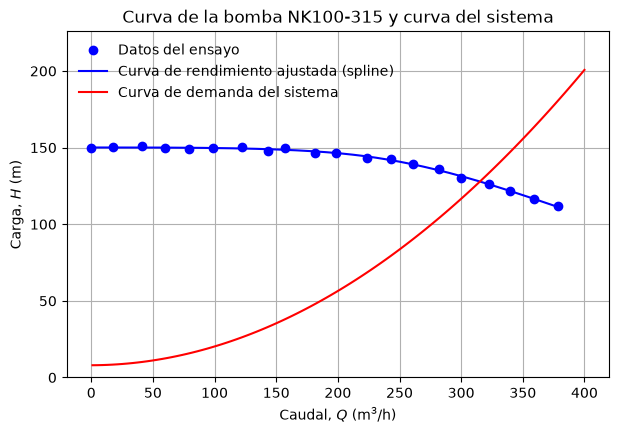

In [66]:
# (d.2)

# Curva de demanda del sistema: 100 puntos en Q ∈ [1, 400] m3/h
Q_sys = np.linspace(1, 400, 100)
H_sys = np.zeros_like(Q_sys)
for k, Q in enumerate(Q_sys):
    H_sys[k] = solve_pump_system(Q)[2]

# Curva de rendimiento ajustada: solo dentro del rango de los nodos
Q_bomba = np.linspace(0, 380, 200)
H_bomba = CubicSplineModel(Q_bomba, *H_pred)

plt.figure(figsize=(7, 4.5))
plt.plot(Qi, Hi, 'bo', label='Datos del ensayo')
plt.plot(Q_bomba, H_bomba, '-b', label='Curva de rendimiento ajustada (spline)')
plt.plot(Q_sys, H_sys, '-r', label='Curva de demanda del sistema')

plt.xlabel(r'Caudal, $Q$ (m$^3$/h)')
plt.ylabel(r'Carga, $H$ (m)')
plt.title('Curva de la bomba NK100-315 y curva del sistema')
plt.ylim(0, 1.5*Hi.max())   # para que la zona de intersección se vea bien
plt.grid()
plt.legend(frameon=False)
plt.show()

**Respuesta (d.3).**

### (e) 0.3 pts — Punto de operación

**(e.1)** Usando código python, determine el **punto de operación del sistema** ($Q_\mathrm{op}$, $H_\mathrm{op}$), dado por la intersección entre la curva de demanda y la curva de rendimiento ajustada en (d).

Luego, determine la potencia entregada por la bomba en el punto de operación, $\dot{W}_\mathrm{bba} = \rho g H_\mathrm{op} Q_\mathrm{op}$.

Utilice `print` para mostrar su resultado.

In [ ]:
# (e.1)
